# Binary Classification Model Assignment

The purpost of this notebook is to develop a machine learning classification model to predict y, the target variable, in the 'eda_classification.csv' dataset. The target is binary, with values of 0 and 1. 

This analysis will begin with exploratory data analysis(EDA) to understand the dataset fully before preparing it for modeling. Data preparation will include necessary cleaning and feature engineering steps that are identified during EDA. A classification model will be trained and evaluated to assess its ability to predict the target variable accurately. 

## 1. Import Libraries and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('eda_classification.csv')


## 2. Initial Data Inspection

In [3]:
print(f'Shape: {df.shape}')
print(f'\nFirst five rows: {df.head()}')
print(f'\nData Types: {df.dtypes}')
print(f'\nMissing Values: {df.isnull().sum()}')
print(f'\nDulplicate Rows: {df.duplicated().sum()}')
print(f'\nTarget Distribution: {df['y'].value_counts()}')

Shape: (9999, 19)

First five rows:           x0    x1         x2         x3        x4         x5         x6  \
0 -17.933519   Jun   6.559220 -14.452810 -4.732855   0.381673   2.563194   
1 -37.214754  July  10.774930 -15.384004 -0.077339  10.983774 -15.210206   
2   0.330441   Aug -19.609972  -9.167911  2.064124  12.071688  12.506141   
3 -13.709765   Aug  -8.011390   6.759264  1.727615  -1.768382  24.039733   
4  -4.202598   May   7.076210 -26.004919 -4.269696  -3.414224   2.115989   

            x7          x8         x9        x10     x11       x12     x13  \
0  ($1,306.52)  -89.394348 -28.454044 -16.201298  -0.01%  0.217010   tesla   
1     ($24.86)  153.032652 -32.557736  69.675903   0.00% -3.584908  Toyota   
2    ($110.85) -141.437276 -20.794952  55.042604   0.00% -3.991366     bmw   
3    ($324.43)   51.039653  -7.046908 -31.424419   0.01%  7.908897  Toyota   
4   $1,213.37   -31.046700  19.061182 -31.525515  -0.01%  0.846719   Honda   

         x14        x15       x16    x

### Observations

Dataset Size: 9,999 rows 19 columns
Variable Types: Some numeric columns are stored as objects. Needs further investigation. 
Missing Values: Some columns have missing values. Needs further investigation. 
Duplicate Rows: None
Target Distribution: No major class imbalance found. 

In [4]:
print(f'Unique Values: {df.nunique(dropna=False)}')
print(f'Object Column Samples:')
for column in df.select_dtypes(include='object').columns:
    print(f'\n{column}:')
    print(df[column].value_counts(dropna=False).head(10))

Unique Values: x0     9997
x1       12
x2     9996
x3     9997
x4     9998
x5     9998
x6     9999
x7     9850
x8     9999
x9     9999
x10    9997
x11      10
x12    9996
x13      11
x14       9
x15    9999
x16    9999
x17       3
y         2
dtype: int64
Object Column Samples:

x1:
x1
July     2709
Jun      2357
Aug      2059
May      1144
sept.     912
Apr       413
Oct       246
Mar       116
Nov        27
Feb        10
Name: count, dtype: int64

x7:
x7
($243.22)     3
NaN           3
$607.10       2
($282.38)     2
($401.01)     2
($126.89)     2
($160.75)     2
$27.91        2
$47.85        2
$1,136.34     2
Name: count, dtype: int64

x11:
x11
0.00%     3914
-0.01%    2409
0.01%     2361
0.02%      581
-0.02%     579
0.03%       73
-0.03%      72
-0.04%       4
0.04%        4
NaN          2
Name: count, dtype: int64

x13:
x13
volkswagon    3132
Toyota        2773
bmw           1837
Honda         1277
tesla          545
chrystler      291
nissan          90
ford            39
merca

## 3. Initial Cleaning Steps

This section will include converting data types and standardizing categorical labels before moving to more in depth data inspection. 

- x1, x13, x14 need standardization
- x7 and x11 need to be converted to numerical data types

In [5]:
categorical_columns = ['x1', 'x13', 'x14', 'x17']

for column in categorical_columns:
    print(f'\n{column} — unique values:')
    print(sorted(df[column].dropna().astype(str).unique()))


x1 — unique values:
['Apr', 'Aug', 'Dev', 'Feb', 'January', 'July', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'sept.']

x13 — unique values:
['Honda', 'Toyota', 'bmw', 'chevrolet', 'chrystler', 'ford', 'mercades', 'nissan', 'tesla', 'volkswagon']

x14 — unique values:
['fri', 'friday', 'monday', 'thur', 'thurday', 'tuesday', 'wed', 'wednesday']

x17 — unique values:
['large', 'medium', 'small']


In [10]:
month_mapping = {
    'January': 'Jan',
    'Feb': 'Feb',
    'Mar': 'Mar',
    'Apr': 'Apr',
    'May': 'May',
    'Jun': 'Jun',
    'July': 'Jul',
    'Aug': 'Aug',
    'sept.': 'Sep',
    'Oct': 'Oct',
    'Nov': 'Nov',
    'Dev': 'Dec'
}

df['x1'] = df['x1'].replace(month_mapping)

brand_mapping = {
    'Honda': 'honda',
    'Toyota': 'toyota',
    'bmw': 'bmw',
    'chevrolet': 'chevrolet',
    'chrystler': 'chrysler',
    'ford': 'ford',
    'mercades': 'mercedes',
    'nissan': 'nissan',
    'tesla': 'tesla',
    'volkswagon': 'volkswagen'
}

df['x13'] = df['x13'].replace(brand_mapping)

weekday_mapping = {
    'fri': 'friday',
    'friday': 'friday',
    'monday': 'monday',
    'thur': 'thursday',
    'thurday': 'thursday',
    'tuesday': 'tuesday',
    'wed': 'wednesday',
    'wednesday': 'wednesday'
}

df['x14'] = df['x14'].replace(weekday_mapping)


In [11]:
for column in ['x1', 'x13', 'x14']:
    print(f"\n{column} unique values:")
    print(sorted(df[column].dropna().unique()))


x1 unique values:
['Apr', 'Aug', 'Dec', 'Feb', 'Jan', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']

x13 unique values:
['bmw', 'chevrolet', 'chrysler', 'ford', 'honda', 'mercedes', 'nissan', 'tesla', 'toyota', 'volkswagen']

x14 unique values:
['friday', 'monday', 'thursday', 'tuesday', 'wednesday']


In [12]:
x7_clean = (
    df['x7']
    .astype('string')
    .str.strip()
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.replace(r'^\((.*)\)$', r'-\1', regex=True)
)

df['x7'] = pd.to_numeric(x7_clean, errors='coerce')

x11_clean = (
    df['x11']
    .astype('string')
    .str.strip()
    .str.replace('%', '', regex=False)
)

df['x11'] = pd.to_numeric(x11_clean, errors='coerce')

print(f'Updated Data Types: {df.dtypes}')
print(f'/nSample Values from x7: {df['x7'].head()}')

print(f'/nSample Values from x11: {df['x11'].head()}')


Updated Data Types: x0     float64
x1      object
x2     float64
x3     float64
x4     float64
x5     float64
x6     float64
x7     Float64
x8     float64
x9     float64
x10    float64
x11    Float64
x12    float64
x13     object
x14     object
x15    float64
x16    float64
x17     object
y        int64
dtype: object
/nSample Values from x7: 0   -1306.52
1     -24.86
2    -110.85
3    -324.43
4    1213.37
Name: x7, dtype: Float64
/nSample Values from x11: 0   -0.01
1     0.0
2     0.0
3    0.01
4   -0.01
Name: x11, dtype: Float64


## 4. Missing Value Inspection

Missing values will be further inspected and dealt with so they do not impact modeling negatively. 

In [14]:
print('Missing values after type conversion:')
print(df.isnull().sum())

print(f'\nTotal missing values: {df.isnull().sum().sum()}')


Missing values after type conversion:
x0     3
x1     0
x2     4
x3     3
x4     2
x5     2
x6     0
x7     3
x8     1
x9     0
x10    3
x11    2
x12    4
x13    1
x14    2
x15    0
x16    1
x17    0
y      0
dtype: int64

Total missing values: 31


In [15]:
missing_per_row = df.isnull().sum(axis=1)

print(f'Rows with missing values: {(missing_per_row > 0).sum()}')

print('\nNumber of missing values per affected row:')
print(missing_per_row[missing_per_row > 0].value_counts().sort_index())

print('\nRows containing missing values:')
display(df.loc[missing_per_row > 0])

Rows with missing values: 31

Number of missing values per affected row:
1    31
Name: count, dtype: int64

Rows containing missing values:


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,y
192,46.253635,Aug,NaN,-34.750810,-3.664199,5.202812,0.593556,-17.43,231.128037,12.050742,-44.509410,-0.01,-7.513439,toyota,wednesday,11.496431,3.087272,small,0
740,11.575782,Jul,NaN,-10.465351,6.683835,5.107881,-17.402725,-71.41,48.832368,-34.006101,-42.819071,0.01,3.767319,honda,wednesday,-7.759168,-4.943520,small,0
1192,-40.809412,Jul,-12.104198,47.917965,NaN,0.149597,-7.495016,125.39,17.340986,28.046385,31.114532,0.02,-2.623253,volkswagen,wednesday,-26.903876,-5.145847,small,0
1597,20.045764,May,NaN,-5.541902,-5.068503,8.119220,-22.913331,441.46,-63.478704,-51.218475,-73.914132,-0.01,-5.820637,volkswagen,wednesday,15.166725,2.529946,small,1
1919,NaN,Jun,-12.029430,-41.680211,-3.755323,-1.906066,-5.101139,300.59,-127.978247,15.344342,-137.632137,0.01,-6.465966,honda,wednesday,-2.430471,-2.403356,small,1
2164,-12.536523,Jun,-18.252567,-8.816692,3.565553,10.109102,34.574570,-248.26,126.810434,15.799768,-110.883920,-0.01,4.364070,tesla,NaN,11.669800,-4.191252,small,1
2190,18.793730,Sep,NaN,-26.958147,3.591022,4.747377,14.421928,881.7,-193.005483,-8.151406,-140.633576,0.0,-2.939647,honda,wednesday,0.208128,1.626390,small,0
2667,-37.135778,Jul,-23.326737,-86.227067,-2.626914,4.935380,9.139259,2410.46,141.319293,-4.813688,NaN,0.01,-2.716700,honda,thursday,-0.751335,-0.012469,small,0
3293,-28.502369,Jul,23.520762,4.519007,0.453145,-4.984521,-8.323547,-660.57,-22.366428,10.017194,-45.002131,<NA>,6.414234,volkswagen,thursday,24.947985,-2.507946,large,1
3320,26.590595,Jun,-28.929406,65.396067,8.926843,-15.986451,-18.055191,1001.17,-91.175236,42.710421,-28.536582,0.0,9.601066,bmw,thursday,-15.212485,NaN,small,0


In [16]:
missing_rows = df[df.isnull().any(axis=1)]
complete_rows = df[df.notnull().all(axis=1)]

print('Target distribution in rows with missing values:')
print(missing_rows['y'].value_counts(normalize=True).mul(100).round(2))

print('\nTarget distribution in complete rows:')
print(complete_rows['y'].value_counts(normalize=True).mul(100).round(2))

# Examine missingness across categorical variables
categorical_columns = ['x1', 'x13', 'x14', 'x17']

for column in categorical_columns:
    print(f"\n{column}: missing rows")
    print(missing_rows[column].value_counts(dropna=False))

    print(f"\n{column}: complete rows")
    print(complete_rows[column].value_counts(normalize=True).mul(100).round(2))

Target distribution in rows with missing values:
y
0    54.84
1    45.16
Name: proportion, dtype: float64

Target distribution in complete rows:
y
0    50.79
1    49.21
Name: proportion, dtype: float64

x1: missing rows
x1
Jul    11
Jun     9
Sep     4
May     3
Aug     2
Apr     1
Oct     1
Name: count, dtype: int64

x1: complete rows
x1
Jul    27.07
Jun    23.56
Aug    20.64
May    11.45
Sep     9.11
Apr     4.13
Oct     2.46
Mar     1.16
Nov     0.27
Feb     0.10
Dec     0.05
Jan     0.01
Name: proportion, dtype: float64

x13: missing rows
x13
toyota        12
volkswagen     6
honda          5
tesla          3
bmw            3
chrysler       1
NaN            1
Name: count, dtype: int64

x13: complete rows
x13
volkswagen    31.36
toyota        27.70
bmw           18.40
honda         12.76
tesla          5.44
chrysler       2.91
nissan         0.90
ford           0.39
mercedes       0.11
chevrolet      0.03
Name: proportion, dtype: float64

x14: missing rows
x14
wednesday    16
thursd

### Decision

The dataset contains 31 rows with missing values. This represents a very small percentage of the observations. The rows with missing values are evenly distributed between classes. Some contained categorical values that cannot be assumed. 

With this information, the rows containig missing values will be dropped from the dataset. 

In [17]:
df = df.dropna().copy()

print(f'Updated Shape: {df.shape}')
print(f'Missing Values: {df.isnull().sum().sum()}')

Updated Shape: (9968, 19)
Missing Values: 0


## 5. Explore Distributions and Characteristics of Variables

This section will explore variables to make determinations for modeling. Findings in this section will guide feature engineering decisions. 

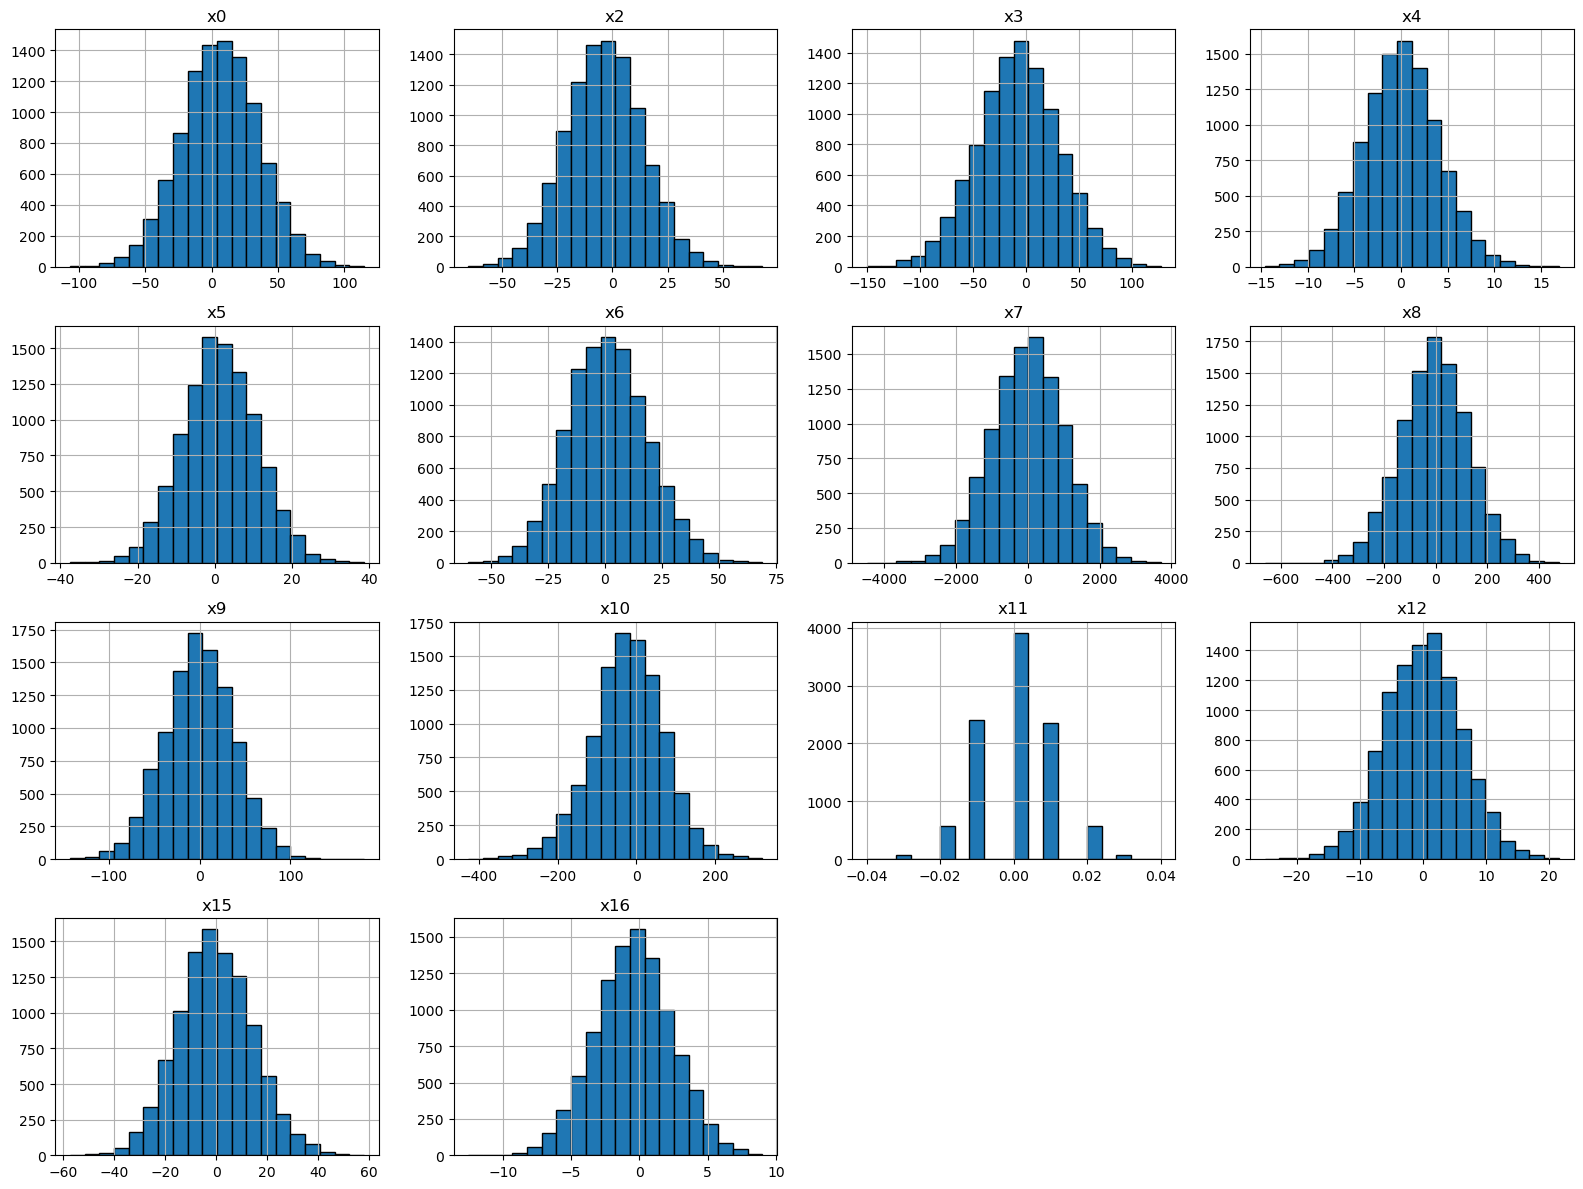

In [18]:
numeric_columns = df.select_dtypes(include='number').columns.drop('y')

df[numeric_columns].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

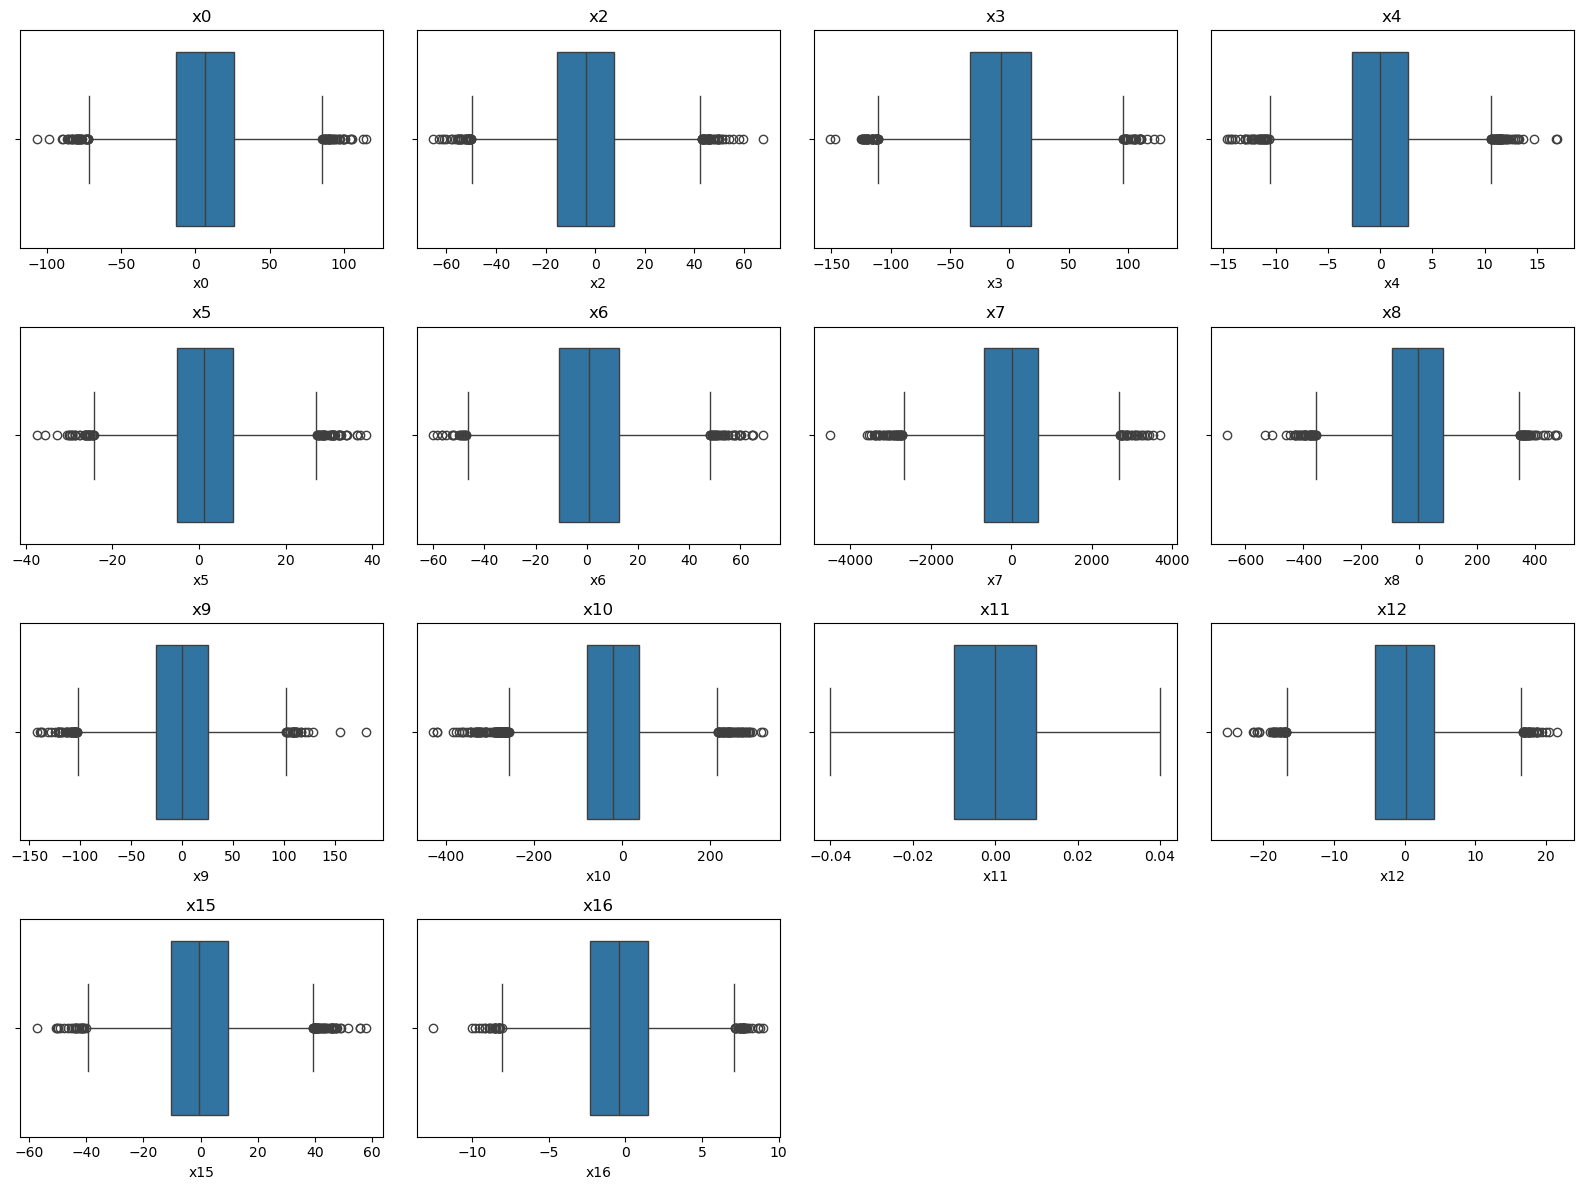

In [19]:
numeric_columns = df.select_dtypes(include='number').columns.drop('y')

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(data=df, x=column, ax=ax)
    ax.set_title(column)

for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

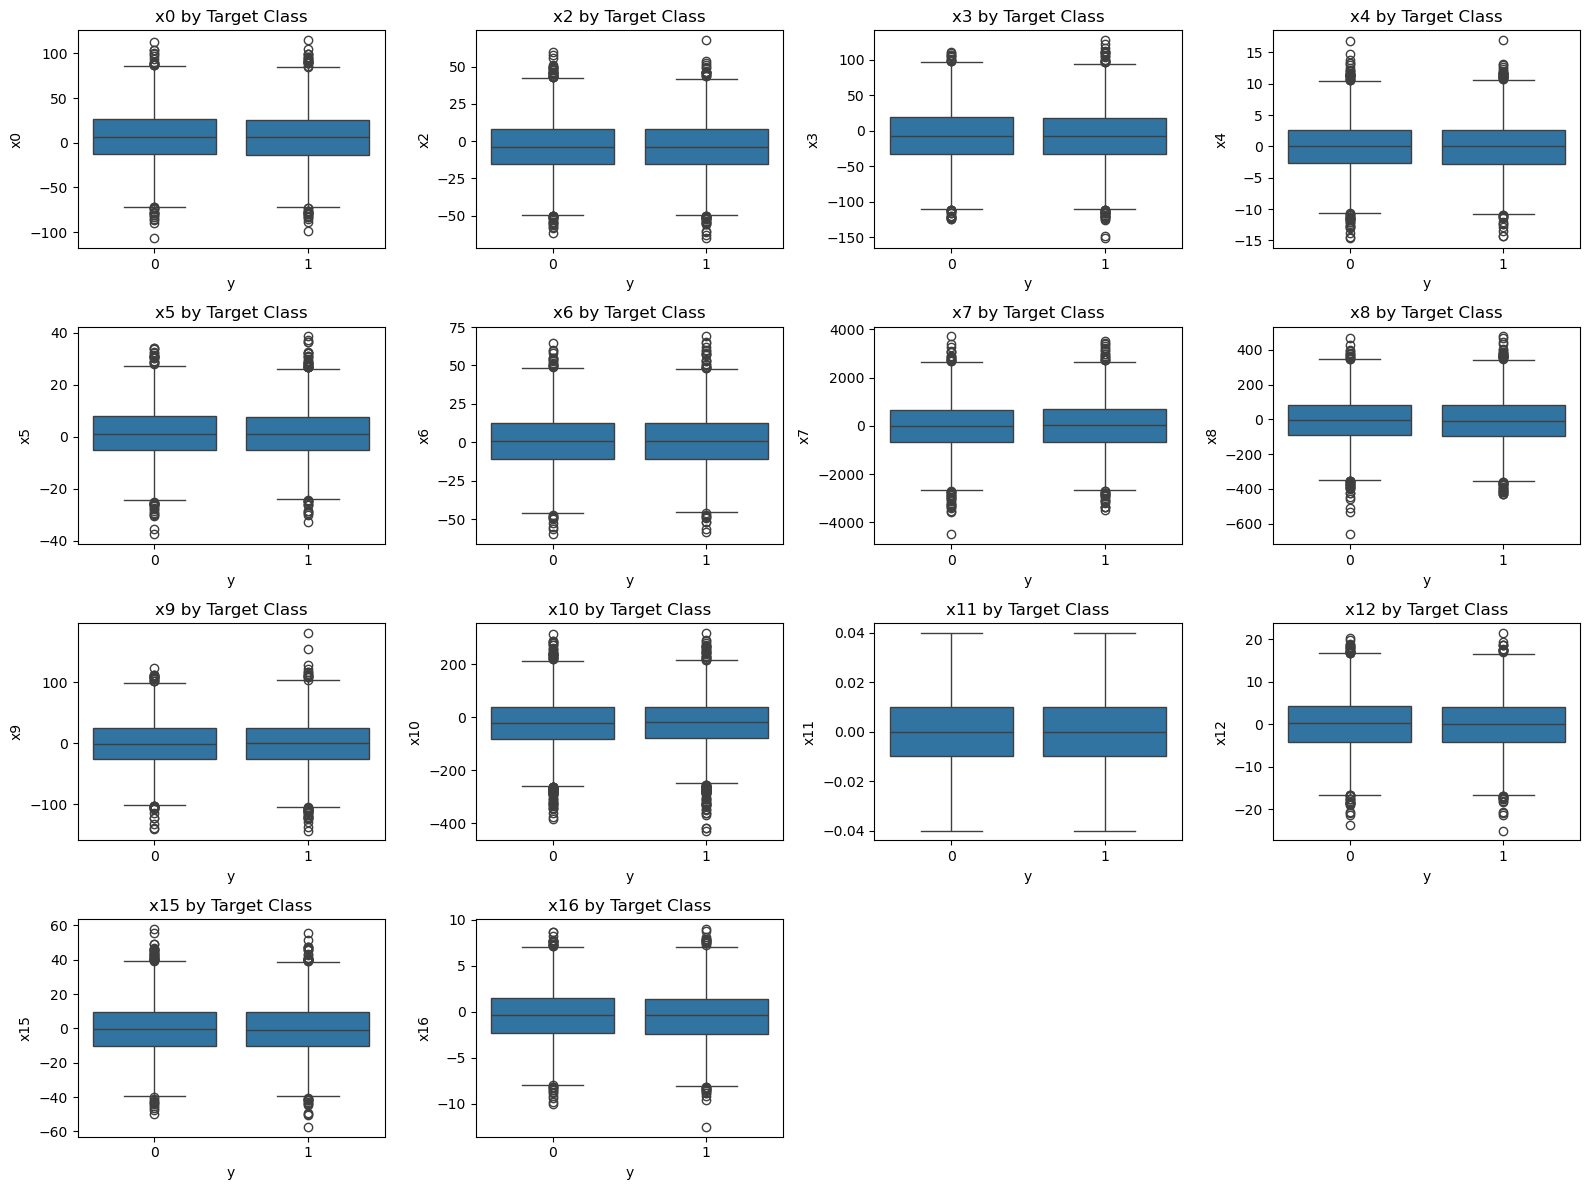

In [20]:
numeric_columns = df.select_dtypes(include='number').columns.drop('y')

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    sns.boxplot(data=df, x='y', y=column, ax=ax)
    ax.set_title(f'{column} by Target Class')

for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

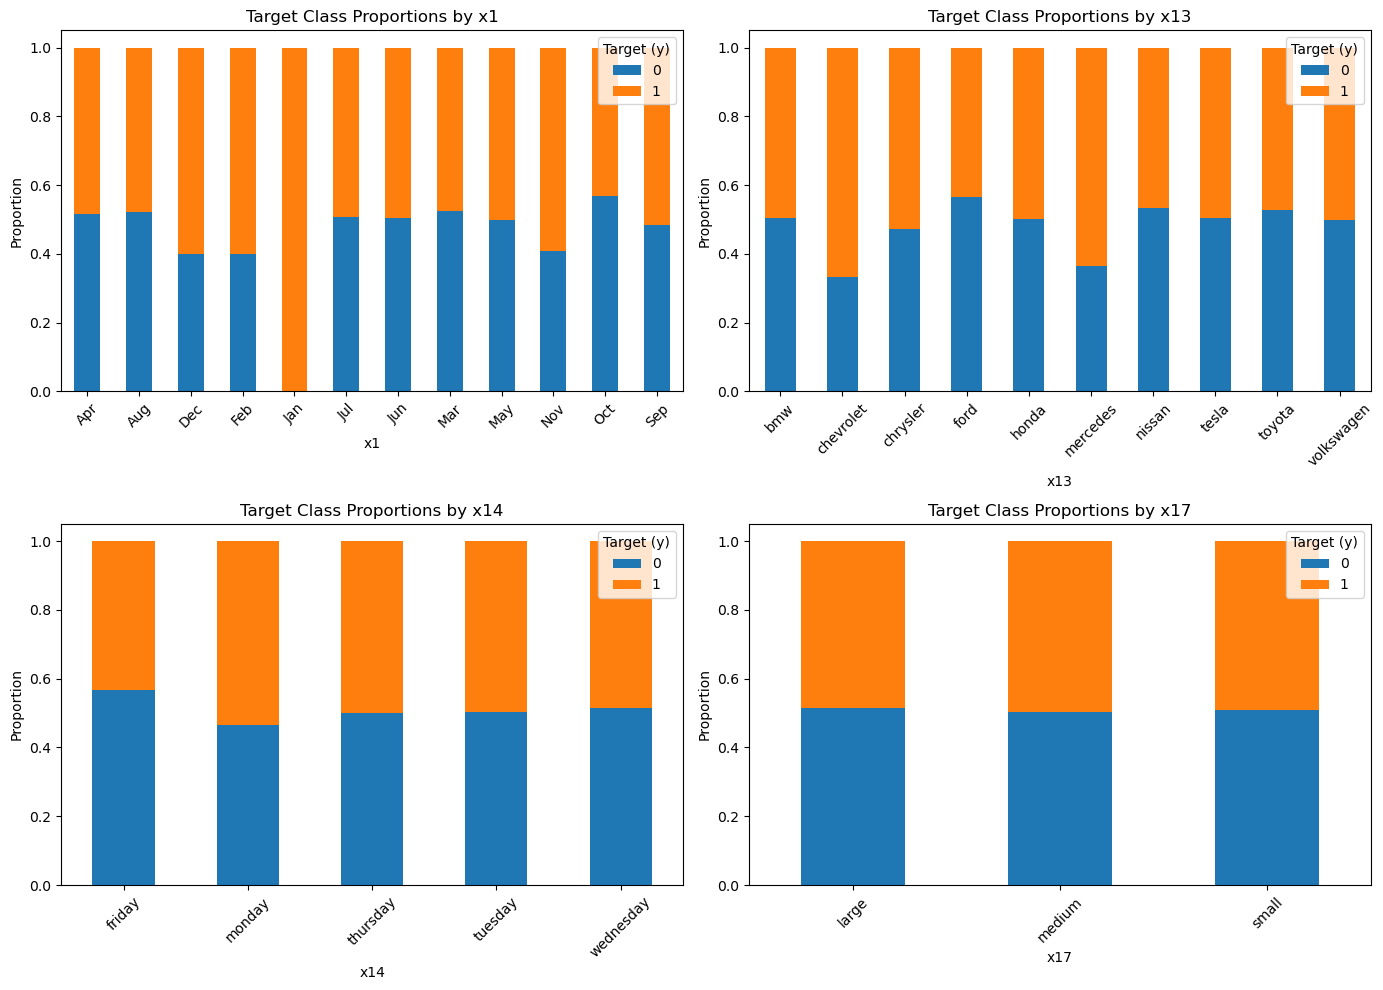

In [21]:
categorical_columns = ['x1', 'x13', 'x14', 'x17']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    proportions = pd.crosstab(
        df[column],
        df['y'],
        normalize='index'
    )

    proportions.plot(
        kind='bar',
        stacked=True,
        ax=ax
    )

    ax.set_title(f'Target Class Proportions by {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Proportion')
    ax.legend(title='Target (y)')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [22]:
categorical_columns = ['x1', 'x13', 'x14', 'x17']

for column in categorical_columns:
    print(f"\nCounts for {column}:")
    print(df[column].value_counts())


Counts for x1:
x1
Jul    2698
Jun    2348
Aug    2057
May    1141
Sep     908
Apr     412
Oct     245
Mar     116
Nov      27
Feb      10
Dec       5
Jan       1
Name: count, dtype: int64

Counts for x13:
x13
volkswagen    3126
toyota        2761
bmw           1834
honda         1272
tesla          542
chrysler       290
nissan          90
ford            39
mercedes        11
chevrolet        3
Name: count, dtype: int64

Counts for x14:
x14
wednesday    5182
thursday     4422
tuesday       213
friday        136
monday         15
Name: count, dtype: int64

Counts for x17:
x17
small     8823
medium     781
large      364
Name: count, dtype: int64


### Observations

There are categorical values with very little counts. This explains some of the observations seen in the visualizations for the data. From here, categorical variables will need to be encoded for the model. 

## 6. Feature Engineering

This section will prepare the features for modeling. This will involve defining the predictor variables and target variable. Certain variables will be encoded so they are useable for the model. One hot encoding will be used for nominal categorical variables. Ordinal categorical variables will be encoded in a way that still preserves the order of the categories. 

In [23]:
X = df.drop(columns=['y'])
y = df['y']

X.shape, y.shape

((9968, 18), (9968,))

In [24]:
X_encoded = X.copy()

size_mapping = {
    'small': 0,
    'medium': 1,
    'large': 2
}

X_encoded['x17'] = X_encoded['x17'].map(size_mapping)

X_encoded = pd.get_dummies(
    X_encoded,
    columns=['x1', 'x13', 'x14'],
    drop_first=True,
    dtype=int
)

In [25]:
X_encoded.shape, X_encoded.select_dtypes(exclude='number').columns.tolist(), X_encoded.head()



((9968, 39),
 [],
           x0         x2         x3        x4         x5         x6       x7  \
 0 -17.933519   6.559220 -14.452810 -4.732855   0.381673   2.563194 -1306.52   
 1 -37.214754  10.774930 -15.384004 -0.077339  10.983774 -15.210206   -24.86   
 2   0.330441 -19.609972  -9.167911  2.064124  12.071688  12.506141  -110.85   
 3 -13.709765  -8.011390   6.759264  1.727615  -1.768382  24.039733  -324.43   
 4  -4.202598   7.076210 -26.004919 -4.269696  -3.414224   2.115989  1213.37   
 
            x8         x9        x10  ...  x13_honda  x13_mercedes  x13_nissan  \
 0  -89.394348 -28.454044 -16.201298  ...          0             0           0   
 1  153.032652 -32.557736  69.675903  ...          0             0           0   
 2 -141.437276 -20.794952  55.042604  ...          0             0           0   
 3   51.039653  -7.046908 -31.424419  ...          0             0           0   
 4  -31.046700  19.061182 -31.525515  ...          1             0           0   
 
    x1

## 7. Train/Test Split

The dataset will be divided into training and testing sets. The training set will be used to develop and tune the classification model, while the testing set will be reserved for final evaluation. An 80/20 split will be used. 

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((7974, 39), (1994, 39), (7974,), (1994,))

## 8. Baseline Classification Model: Logistic Regression

Logistic regression will be used as the baseline model to predict the binary target variable y. After fitting the model and generating predictions, it will be evaluated using cross-validation. 

After running the model once, it suggested I scale the data so I went back and added a scaler. 

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1e6, max_iter=1000)
)
        
log_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](39,)","['x0','x2','x3',...,'x14_thursday','x14_tuesday','x14_wednesday']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,39
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [30]:
prob_log_reg = log_reg.predict_proba(X_train)
prob_log_reg[:10]

array([[0.52039028, 0.47960972],
       [0.56276372, 0.43723628],
       [0.50795684, 0.49204316],
       [0.5128879 , 0.4871121 ],
       [0.49685231, 0.50314769],
       [0.49574334, 0.50425666],
       [0.56094655, 0.43905345],
       [0.51170758, 0.48829242],
       [0.53913941, 0.46086059],
       [0.46719585, 0.53280415]])

In [31]:
y_pred_log_reg = log_reg.predict(X_train)
y_pred_log_reg[:10]

array([0, 0, 0, 0, 1, 1, 0, 0, 0, 1])

In [32]:
pd.Series(
    log_reg.named_steps['logisticregression'].coef_[0],
    index=X_train.columns
).sort_values(ascending=True)

x13_toyota       -0.057599
x8               -0.042527
x1_Oct           -0.028581
x15              -0.024365
x1_Aug           -0.023614
x13_nissan       -0.023020
x2               -0.020371
x17              -0.019866
x16              -0.013767
x13_ford         -0.013181
x13_tesla        -0.009591
x0               -0.008343
x5               -0.008338
x1_Jun           -0.007923
x13_volkswagen   -0.006733
x1_Mar           -0.005593
x4               -0.002255
x13_honda         0.002557
x1_May            0.004523
x12               0.004786
x1_Jul            0.005802
x14_monday        0.006182
x7                0.008455
x6                0.008799
x1_Feb            0.009142
x9                0.009863
x13_mercedes      0.013351
x3                0.014280
x11               0.017463
x1_Sep            0.020175
x13_chrysler      0.020791
x1_Dec            0.024082
x14_tuesday       0.027197
x1_Nov            0.039618
x10               0.045798
x14_wednesday     0.050039
x14_thursday      0.067460
x

In [33]:
from sklearn.metrics import accuracy_score

accuracy_log_reg = accuracy_score(
    y_true=y_train,
    y_pred=y_pred_log_reg
)

accuracy_log_reg

0.5242036619011788

print("Actual training labels:")
print(y_train.value_counts())

print("\nPredicted training labels:")
print(pd.Series(y_pred_log_reg).value_counts())

print("\nConfusion matrix:")
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_train, y_pred_log_reg))

## 9.Random Forest Classification Model

A random forest classifier will be used to compare to the logistic regression model. 

In [37]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_train)

accuracy_rf = accuracy_score(y_train, y_pred_rf)

accuracy_rf
                            

1.0

## 10. Evaluate Models Using Test Data

The test data will now be used to evaluate both models. 

In [38]:
y_pred_log_reg_test = log_reg.predict(X_test)
accuracy_log_reg_test = accuracy_score(
    y_test, y_pred_log_reg_test
)

y_pred_rf_test = rf.predict(X_test)
accuracy_rf_test = accuracy_score(
    y_test, y_pred_rf_test
)

print(f"Logistic Regression Test Accuracy: {accuracy_log_reg_test:.2%}")
print(f"Random Forest Test Accuracy: {accuracy_rf_test:.2%}")

Logistic Regression Test Accuracy: 50.80%
Random Forest Test Accuracy: 49.50%


## 11. Interpretation of Models

Two classification models were developed and evaluated: Logistic Regression and Random Forest. When the test data was used, both models had around 50% accuracy. These results suggest that neither model found meaningful patterns with the features used. 

The random forest model performed better than the logistic regression on the training data, however a 100% accuracy suggests overfitting. 

At this point in the process, it would be appropriate to revisit the features and look more into relationships among them. An alternative modeling strategy may need to be used improve the performance of modeling. 